# 46. Permutations
**Difficulty:** 🟡 Medium · **Topic:** Backtracking · **Pattern:** [Permutations](README.md) · **LeetCode:** https://leetcode.com/problems/permutations/

## 💡 Concepts

**Core concept(s):** **backtracking over "which unused number goes next"**, with a `used[]` array as the second piece of state.

**Why it applies here:**
- A permutation is built one slot at a time: slot 0 gets any of the `n` numbers, slot 1 any of the remaining `n - 1`, and so on.
- That is a tree of choices with `n · (n-1) · ... · 1 = n!` leaves, one per permutation. Backtracking walks that tree depth-first.
- Order matters (`[1,2,3]` and `[2,1,3]` are different answers), so every level must be allowed to pick **any** unused number, including ones with a smaller index. A forward-only `start` index (Subsets, Combinations) cannot do that; a `used[]` array can.

**Key intuition:**
- Keep one growing `path`. Add a number, recurse to fill the next slot, then remove it and try the next number.
- `used[i]` answers "is `nums[i]` already in the path?" in `O(1)`.
- When `len(path) == n`, every slot is filled: record a **copy** of the path.

---

### 📚 What is a Permutation?
- A **permutation** of a list is one ordering of all its elements, each used exactly once.
- `[1, 2, 3]` has `3! = 6` permutations: `[1,2,3]`, `[1,3,2]`, `[2,1,3]`, `[2,3,1]`, `[3,1,2]`, `[3,2,1]`.
- **Counting:** `n` choices for the first slot × `n - 1` for the second × ... × `1` = `n!`.
- `n!` grows faster than any power of 2: `6! = 720`, `9! = 362,880`, `10! = 3,628,800`. That is why LeetCode caps `n` at 6.
- **In Python:** `itertools.permutations(nums)` yields them as tuples (a C-level library routine; in an interview, write it yourself).

### 📚 What is Recursion?
- A **recursive** function solves a problem by calling itself on a smaller version of the same problem.
- It needs a **base case** that stops the calls (here: the path is full).
- Each call gets its own frame on the **call stack**; when a call returns, its caller continues from where it left off.
- **Complexity:** the stack holds one frame per level of depth → `O(depth)` extra space. Here the depth is `n`.
- **In Python:** an ordinary `def` calling itself; the default recursion limit (~1000) is far above `n = 6`.

### 📚 What is Backtracking?
- **Backtracking** builds a solution one choice at a time and **undoes** each choice after exploring it, so the same `path` can be reused for the next choice.
- Every step has three moves: **choose** (change the state), **explore** (recurse), **un-choose** (restore the state exactly).
- It is a **depth-first search (DFS)** over a tree of choices: go deep along one branch until it is complete, then back up one level and try the next option.
- **Complexity:** (number of leaves) × (work per leaf). For permutations: `n!` leaves × `O(n)` to copy each one = `O(n · n!)`.
- **In Python:** a nested `def backtrack()` that closes over `path`, `used` and `out` lists; `path.append` / `path.pop` are `O(1)`.

### 📚 What is a `used[]` (visited) array?
- A list of booleans, one per input position: `used[i] is True` while `nums[i]` sits in the current path.
- Lookup and update are `O(1)` by index, instead of an `O(n)` scan `nums[i] in path`.
- It is part of the state, so it must be **un-chosen too**: `used[i] = False` right after `path.pop()`.
- **In Python:** `used = [False] * len(nums)`.

---

**Prerequisite knowledge:**
- Python lists: `append`, `pop`, slicing `p[:k]`, and why `path[:]` makes a copy.
- The choose / explore / un-choose template from [Deep Dive 21 — Backtracking](../../../deep_dive/21_Backtracking/README.md).

## 📝 Problem

Given an array `nums` of **distinct** integers, return **all possible permutations** (orderings) of it. Any order of the answer list is accepted.

**Example 1**
```
nums = [1,2,3]  ->  [[1,2,3],[1,3,2],[2,1,3],[2,3,1],[3,1,2],[3,2,1]]
```

**Example 2**
```
nums = [0,1]  ->  [[0,1],[1,0]]
```

**Example 3**
```
nums = [1]  ->  [[1]]
```

**Constraints:** `1 <= nums.length <= 6`, `-10 <= nums[i] <= 10`, all integers of `nums` are **unique**.

> Every approach must output all `n!` orderings, each of length `n`, so `O(n · n!)` time is the floor for all of them. The approaches differ in **how** they build the orderings and how much extra memory they keep. Three approaches: an iterative build-up that inserts each new number at every position, the backtracking template with `used[]` (the pattern), and an in-place swap variant of the same DFS.

In [1]:
from typing import List
import itertools                       # only as a reference answer in the checks below

### Approach 1 — Build up by inserting at every position (iterative)

**Idea:**
1. Start with one empty ordering: `[[]]`.
2. Take the numbers one at a time. For each ordering built so far (length `k`), insert the new number at each of the `k + 1` gaps, making `k + 1` new orderings.
3. After the last number, every ordering has length `n` and there are `1 · 2 · ... · n = n!` of them.

```
[]  --add 1-->  [1]  --add 2-->  [2,1] [1,2]  --add 3-->  [3,2,1] [2,3,1] [2,1,3]  [3,1,2] [1,3,2] [1,2,3]
```

It is how you would list them by hand, and it needs no recursion. `itertools.permutations(nums)` is the library one-liner that produces the same set; the checks below use it as the reference answer.

**Time complexity:** `O(n · n!)` — round `k` builds `k!` lists of length `k`; summed over all rounds that is `(n+1)! - 1 = O(n · n!)`, dominated by the last round.

**Space complexity:** `O(n!)` extra on top of the `O(n · n!)` output — the previous round's `(n-1)!` partial orderings (length `n - 1` each) stay alive while the last round is built.

In [2]:
def permute_insert(nums: List[int]) -> List[List[int]]:
    perms = [[]]                                   # one ordering of zero numbers
    for x in nums:                                 # add the numbers one at a time
        perms = [p[:k] + [x] + p[k:]               # put x into gap k of an existing ordering...
                 for p in perms
                 for k in range(len(p) + 1)]       # ...for every one of the len(p) + 1 gaps
    return perms

### Approach 2 — Backtracking with a `used[]` array (optimal · pattern template)

**Idea:** the [Permutations](README.md) template — choose / explore / un-choose, where the choice is "which unused number fills the next slot".
1. `path` is the ordering being built; `used[i]` is `True` while `nums[i]` is in `path`.
2. **Base case:** `len(path) == len(nums)` → every slot is filled → append a **copy** `path[:]`.
3. Otherwise loop over **every** index `i` (not from a `start`, because order matters). Skip `i` if `used[i]`.
4. **Choose:** `used[i] = True; path.append(nums[i])`. **Explore:** `backtrack()`. **Un-choose:** `path.pop(); used[i] = False` — both pieces of state, in reverse order.

```
                      []
          /           |           \
       [1]           [2]           [3]          slot 0: 3 choices
      /   \         /   \         /   \
  [1,2] [1,3]   [2,1] [2,3]   [3,1] [3,2]       slot 1: 2 choices
    |     |       |     |       |     |
 [1,2,3] [1,3,2] [2,1,3] [2,3,1] [3,1,2] [3,2,1]  slot 2: 1 choice -> 3! = 6 leaves
```

**Time complexity:** `O(n · n!)` — `n!` leaves, each copied in `O(n)`; every internal node of the tree also scans the `n` indices, and there are fewer than `e · n!` internal nodes, so the total stays `O(n · n!)`.

**Space complexity:** `O(n)` extra — `path`, `used` and the recursion stack are each at most `n` deep (output not counted).

> Same order of time as Approach 1. Backtracking is the interview target because it is the one template behind Subsets, Combinations, Permutations II, N-Queens and Word Search: pruning checks and duplicate skips slot in before the choose line.

In [3]:
def permute_backtrack(nums: List[int]) -> List[List[int]]:
    out, path, used = [], [], [False] * len(nums)
    def backtrack():
        if len(path) == len(nums):                 # every slot filled: one complete ordering
            out.append(path[:])                    # record a COPY; path keeps changing
            return
        for i in range(len(nums)):                 # any slot may take any number, not just later ones
            if used[i]:
                continue                           # already on the path
            used[i] = True;  path.append(nums[i])  # CHOOSE (two pieces of state)
            backtrack()                            # EXPLORE the next slot
            path.pop();      used[i] = False       # UN-CHOOSE (both pieces, reverse order)
    backtrack()
    return out

### Approach 3 — Backtracking by swapping in place (alternate)

**Idea:** the same DFS, but the array itself is the path, so no `used[]` is needed.
1. `nums[:first]` is the fixed prefix; `nums[first:]` is exactly the set of numbers not used yet.
2. For each `i` from `first` to the end, **swap** `nums[i]` into slot `first` (choose), recurse on `first + 1` (explore), then **swap back** (un-choose).
3. When `first == len(nums)`, the whole array is one permutation: append a copy.

The swaps shuffle the unused tail, so the output order differs from Approach 2 (`[3,2,1]` comes before `[3,1,2]`). LeetCode accepts any order; the checks compare sorted outputs.

**Time complexity:** `O(n · n!)` — same tree shape as Approach 2, `n!` leaves copied in `O(n)`.

**Space complexity:** `O(n)` extra — one working copy of `nums` and a recursion stack `n` deep (output not counted).

In [4]:
def permute_swap(nums: List[int]) -> List[List[int]]:
    nums = nums[:]                                 # work on a copy: the caller's list stays untouched
    out = []
    def backtrack(first):
        if first == len(nums):                     # every slot fixed
            out.append(nums[:])                    # record a COPY of the whole array
            return
        for i in range(first, len(nums)):          # nums[first:] = the numbers not placed yet
            nums[first], nums[i] = nums[i], nums[first]   # CHOOSE: move nums[i] into slot `first`
            backtrack(first + 1)                          # EXPLORE the remaining slots
            nums[first], nums[i] = nums[i], nums[first]   # UN-CHOOSE: swap back
    backtrack(0)
    return out

In [5]:
# Correctness check
import math, random

tests = [
    ([1, 2, 3], [[1, 2, 3], [1, 3, 2], [2, 1, 3], [2, 3, 1], [3, 1, 2], [3, 2, 1]]),   # LeetCode example 1
    ([0, 1],    [[0, 1], [1, 0]]),                                                    # LeetCode example 2
    ([1],       [[1]]),                                                               # LeetCode example 3
    ([-1, 5],   [[-1, 5], [5, -1]]),                                                  # negative values
]
for nums, exp in tests:
    a, b, c = permute_insert(nums), permute_backtrack(nums), permute_swap(nums)
    print(f"{str(nums):10} -> {len(b)} permutations, backtrack order: {b}")
    assert sorted(a) == sorted(b) == sorted(c) == sorted(exp), f"mismatch on {nums}"

print("permute_swap([1,2,3]) order:", permute_swap([1, 2, 3]))   # different order, same set

# Every length allowed by the constraints: n! distinct orderings, each a rearrangement of nums
rng = random.Random(46)
for n in range(1, 7):
    nums = rng.sample(range(-10, 11), n)           # distinct values, as the problem guarantees
    ref = sorted(list(p) for p in itertools.permutations(nums))
    for f in (permute_insert, permute_backtrack, permute_swap):
        got = f(nums)
        assert len(got) == math.factorial(n), (f.__name__, n)
        assert len({tuple(p) for p in got}) == len(got), (f.__name__, "duplicate ordering")
        assert sorted(got) == ref, (f.__name__, nums)
    print(f"n = {n}: all three return the same {math.factorial(n)} permutations as itertools")

# The input list must not be modified
nums = [3, 1, 2]
for f in (permute_insert, permute_backtrack, permute_swap):
    f(nums)
assert nums == [3, 1, 2]

print("\nAll tests passed")

[1, 2, 3]  -> 6 permutations, backtrack order: [[1, 2, 3], [1, 3, 2], [2, 1, 3], [2, 3, 1], [3, 1, 2], [3, 2, 1]]
[0, 1]     -> 2 permutations, backtrack order: [[0, 1], [1, 0]]
[1]        -> 1 permutations, backtrack order: [[1]]
[-1, 5]    -> 2 permutations, backtrack order: [[-1, 5], [5, -1]]
permute_swap([1,2,3]) order: [[1, 2, 3], [1, 3, 2], [2, 1, 3], [2, 3, 1], [3, 2, 1], [3, 1, 2]]
n = 1: all three return the same 1 permutations as itertools
n = 2: all three return the same 2 permutations as itertools
n = 3: all three return the same 6 permutations as itertools
n = 4: all three return the same 24 permutations as itertools
n = 5: all three return the same 120 permutations as itertools
n = 6: all three return the same 720 permutations as itertools

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured** by timing each approach on growing inputs.

Here the input size can't double: the output alone has `n!` lists, so `n = 12` would already be ~479 million orderings. Instead `n` grows **by 1** (5 → 9) and we compare against what `O(n · n!)` predicts for each step:

| `n` → `n + 1` | predicted ratio `(n+1)·(n+1)! / (n·n!) = (n+1)²/n` |
|---------------|------------------------------------------|
| 5 → 6 | ≈ **7.2×** |
| 6 → 7 | ≈ **8.2×** |
| 7 → 8 | ≈ **9.1×** |
| 8 → 9 | ≈ **10.1×** |

So the ratio is not constant (as it would be for `O(n)` or `O(n²)` under doubling): it **grows by about 1 with every +1 in `n`**, because each extra element multiplies the work by roughly `n`. The input is any list of `n` distinct numbers: every input of size `n` produces exactly `n!` orderings, so there is no easier or harder case. `itertools.permutations` (implemented in C) is timed as a reference line: same growth, smaller constant.

The garbage collector is switched off while timing (as `timeit` does by default). Each run creates up to `9! = 362,880` small lists; with the collector on, its periodic full scans over all those live lists add cost that grows with the output size and blurs the `n · n!` shape.

**Reading the output:** compare each row's ratio with the table above, not with the helper's generic per-doubling footer (that footer assumes `n` doubles). All four lines should climb by roughly 1× per row. The constants differ: the build-up does its copying with list slicing, which runs in C, so in CPython it can beat the recursive versions despite the same Big-O; backtracking is still the version to know, because pruning and duplicate-skipping only fit into the recursive template.


insert build-up O(n*n!)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        5 |       0.02 |           n/a
        6 |       0.12 |         5.65x
        7 |       0.80 |         6.84x
        8 |       6.62 |         8.30x


        9 |      70.59 |        10.66x



backtrack used[] O(n*n!)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        5 |       0.05 |           n/a
        6 |       0.29 |         6.09x
        7 |       2.07 |         7.14x
        8 |      19.55 |         9.46x


        9 |     193.50 |         9.90x

backtrack swap O(n*n!)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        5 |       0.05 |           n/a
        6 |       0.30 |         6.31x
        7 |       2.02 |         6.81x
        8 |      16.51 |         8.18x


        9 |     147.57 |         8.94x

itertools reference (C)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        5 |       0.00 |           n/a
        6 |       0.02 |         5.34x
        7 |       0.19 |         8.93x
        8 |       1.88 |         9.96x
        9 |      22.32 |        11.89x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


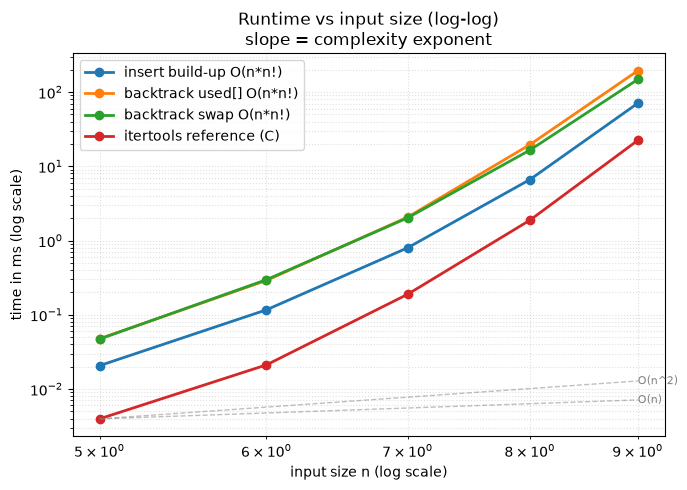

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (list(range(n)),)          # any n distinct values: always exactly n! orderings
solutions = {
    "insert build-up O(n*n!)": permute_insert,
    "backtrack used[] O(n*n!)": permute_backtrack,
    "backtrack swap O(n*n!)": permute_swap,
    "itertools reference (C)": lambda nums: list(itertools.permutations(nums)),
}
sizes = [5, 6, 7, 8, 9]               # +1 per step, not doubling: n! explodes

import gc
gc.disable()                          # like timeit: keep the cyclic GC from rescanning ~n! live lists mid-run
try:
    benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)
finally:
    gc.enable()

## 🧩 Patterns Learned

- **Pattern:** [Permutations](README.md) — choose / explore / un-choose where the choice is "which **unused** number fills the next slot"; a `used[]` array (or swapping into place) replaces the forward-only `start` index of Subsets and Combinations.
- **Order matters → loop over all indices every level.** `for i in range(len(nums))` + `if used[i]: continue`. A `start` index would only produce one ordering per set, which is what Subsets / Combinations want.
- **Un-choose every piece of state you chose.** Two pieces here (`path` and `used`), restored in reverse order. Forgetting `used[i] = False` starves every later branch after the first full permutation.
- **Record a copy.** `out.append(path[:])`, not `out.append(path)`: otherwise every entry aliases the same list, which ends up empty.
- **Cost = number of leaves × cost per leaf:** `n!` orderings × `O(n)` copy = `O(n · n!)`. No approach can beat it, because the output itself has that size.
- **Swap variant:** the array is the path; `nums[first:]` is the unused set; swap in, recurse, swap back. `O(n)` extra space and no `used[]`, but the output order is not lexicographic.
- **Signal:** "all permutations", "all orderings / arrangements", "every possible order", small `n` (≤ 8–10).
- **Related problems (variants):** Permutations II (LC 47, duplicates: sort, then skip `nums[i] == nums[i-1] and not used[i-1]`), Next Permutation (LC 31, one step in lexicographic order, no recursion), Permutation Sequence (LC 60, the k-th permutation by counting `(n-1)!` blocks), Letter Case Permutation (LC 784).
- **Common pitfalls:**
  1. Using `for i in range(start, n)` copied from Subsets: you get combinations, not orderings.
  2. Appending `path` instead of `path[:]`.
  3. Popping `path` but leaving `used[i] = True`.
  4. In the swap version, forgetting to swap back, so later branches see a scrambled array.